In [77]:
# Data manipulation and numerical operations
import pandas as pd   # For data manipulation and analysis
import numpy as np    # For numerical operations

import shap  # package used to calculate Shap values

# Data visualization libraries
import matplotlib.pyplot as plt   # For plotting and visualizations
import graphviz   # For visualizing decision trees
import seaborn as sns

# Scikit-learn: Model selection and evaluation
from sklearn.model_selection import train_test_split   # For splitting the data into training and testing sets
from sklearn.metrics import accuracy_score, classification_report  # For evaluating model performance
from sklearn.metrics import roc_curve, roc_auc_score  # For calculating ROC curve and AUC
from sklearn.metrics import confusion_matrix

# Scikit-learn: Preprocessing
from sklearn.preprocessing import LabelEncoder   # For encoding categorical labels into numeric values
from sklearn.preprocessing import OneHotEncoder  # For encoding categorical features using one-hot encoding

# Scikit-learn: Machine learning model
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report
from catboost import CatBoostClassifier

# Scikit-learn: Tree visualization
from sklearn.tree import export_graphviz  # For exporting decision trees in DOT format
from sklearn.tree import plot_tree  # For plotting decision trees

from scipy import stats

plt.style.use('fivethirtyeight')
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

In [78]:
# Specify the file path to the CSV file containing the thyroid cancer recurrence data
csv_path = "../data/thyroid_diff.csv"

# Read the CSV file into a DataFrame using pandas
df = pd.read_csv(csv_path)

df = df.drop(['Focality', 'Stage','Risk', 'T', 'N', 'M'], axis='columns')

# Display the first few rows of the DataFrame to get a quick overview of the data
df.head()

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Excellent,No


In [79]:
# Label encode features with only 2 values
le = LabelEncoder()

# TODO: Input column names that only have 2 values
columns_to_encode = ['Gender']

for column in columns_to_encode:
  df[column] = le.fit_transform(df[column])

# df.head()

In [80]:
# Label encoding yes or no values

# Define mapping
mapping = {'No': 0, 'Yes': 1}

# TODO: Insert names of columns that have Yes or No values
boolean_columns = ['Smoking','Hx Smoking','Hx Radiotherapy','Recurred']
df[boolean_columns] = df[boolean_columns].map(mapping.get)

# df.head()

In [81]:
# TODO: Define mapping for 'Physical Examination'
mapping = {'Normal': 0, 'Diffuse goiter':1, 'Single nodular goiter-left':2, 'Single nodular goiter-right':2,'Multinodular goiter':3}

df['Physical Examination'] = df['Physical Examination'].map(mapping)

if np.isnan(df['Physical Examination'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

In [82]:
# TODO: Define mapping for 'Adenopathy'
mapping = {'No': 0, 'Right':1, 'Left':1, 'Posterior':2,'Bilateral':3,'Extensive':4}

df['Adenopathy'] = df['Adenopathy'].map(mapping)

if np.isnan(df['Adenopathy'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

In [83]:
# TODO: Define mapping for 'Pathology'
mapping = {'Micropapillary':0,'Papillary':1, 'Follicular':2, 'Hurthle cell':3}

df['Pathology'] = df['Pathology'].map(mapping)

if np.isnan(df['Pathology'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

In [84]:
# TODO: Define mapping for 'Response'
mapping = {'Excellent':0, 'Indeterminate':1, 'Biochemical Incomplete':2, 'Structural Incomplete':3}

df['Response'] = df['Response'].map(mapping)

if np.isnan(df['Response'].unique()).any():
  raise ValueError('Your output has NaN values. Check your mapping inputs to make sure they exactly match the unique values.')

# df.head()

### 1.1.3 One-Hot Encoding

In [85]:
# Initialize a OneHotEncoder object
ohe = OneHotEncoder()

# Fit the OneHotEncoder to the 'Thyroid Function' column of the dataframe 'df'
# and transform it into a one-hot encoded array. The 'toarray()' method
# converts the sparse matrix output into a dense numpy array.
ohe.fit_transform(df[['Thyroid Function']]).toarray()

array([[0., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0.],
       ...,
       [0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

In [86]:
# Fit the OneHotEncoder to the 'Thyroid Function' column of the dataframe 'df'
# and transform it into a one-hot encoded array. The 'toarray()' method
# converts the sparse matrix output into a dense numpy array.
feature_array = ohe.fit_transform(df[['Thyroid Function']]).toarray()

# Get the category labels from the fitted OneHotEncoder
feature_labels = ohe.categories_

# Convert the list of arrays (from ohe.categories_) to a flattened numpy array
feature_labels = np.array(feature_labels).ravel()

# Create a DataFrame from the one-hot encoded array with column names set to the flattened feature labels
pd.DataFrame(feature_array, columns=feature_labels)

,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...
378,0.0,0.0,1.0,0.0,0.0
379,0.0,0.0,1.0,0.0,0.0
380,0.0,0.0,1.0,0.0,0.0
381,1.0,0.0,0.0,0.0,0.0


In [87]:
# Create a DataFrame from the one-hot encoded array (feature_array)
# using the flattened feature labels (feature_labels) as column names
features = pd.DataFrame(feature_array, columns=feature_labels)

# Concatenate the original dataframe (df) and the new one-hot encoded features (features)
# along the columns (axis=1). This results in a combined DataFrame with both the original
# and one-hot encoded features.
pd.concat([df, features], axis=1)

,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Response,Recurred,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,27,0,0,0,0,Euthyroid,2,0,0,1,0,0.0,0.0,1.0,0.0,0.0
1,34,0,0,1,0,Euthyroid,3,0,0,0,0,0.0,0.0,1.0,0.0,0.0
2,30,0,0,0,0,Euthyroid,2,0,0,0,0,0.0,0.0,1.0,0.0,0.0
3,62,0,0,0,0,Euthyroid,2,0,0,0,0,0.0,0.0,1.0,0.0,0.0
4,62,0,0,0,0,Euthyroid,3,0,0,0,0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,72,1,1,1,1,Euthyroid,2,1,1,2,1,0.0,0.0,1.0,0.0,0.0
379,81,1,1,0,1,Euthyroid,3,4,1,3,1,0.0,0.0,1.0,0.0,0.0
380,72,1,1,1,0,Euthyroid,3,3,1,3,1,0.0,0.0,1.0,0.0,0.0
381,61,1,1,1,1,Clinical Hyperthyroidism,3,4,3,3,1,1.0,0.0,0.0,0.0,0.0


In [88]:
# Concatenate the original dataframe (df) with the new one-hot encoded features (features)
# along the columns (axis=1). This adds the one-hot encoded columns to the original dataframe.
df = pd.concat([df, features], axis=1)

# Drop the original 'Thyroid Function' column from the dataframe
# as it has been replaced by the one-hot encoded columns.
df = df.drop(['Thyroid Function'], axis='columns')

# Display the first few rows of the updated dataframe to inspect the result.
# df.head()

In [89]:
#apply Box-Cox transformation to 'Age' column
age_boxcox, _ = stats.boxcox(df['Age'])

#apply Min-Max scaling to the transformed 'Age' column
scaler = MinMaxScaler()
age_scaled = scaler.fit_transform(age_boxcox.reshape(-1, 1)).flatten()

#replace 'Age' column with the scaled values
df['Age'] = age_scaled

# df.head()

In [90]:
# Drop the 'Recurred' column from the DataFrame to create the input features DataFrame
inputs = df.drop('Recurred', axis='columns')

# Select the target column 'Recurred' from the DataFrame to create the target DataFrame
target = df['Recurred']

inputs.head()


,Age,Gender,Smoking,Hx Smoking,Hx Radiotherapy,Physical Examination,Adenopathy,Pathology,Response,Clinical Hyperthyroidism,Clinical Hypothyroidism,Euthyroid,Subclinical Hyperthyroidism,Subclinical Hypothyroidism
0,0.363135,0,0,0,0,2,0,0,1,0.0,0.0,1.0,0.0,0.0
1,0.500483,0,0,1,0,3,0,0,0,0.0,0.0,1.0,0.0,0.0
2,0.426257,0,0,0,0,2,0,0,0,0.0,0.0,1.0,0.0,0.0
3,0.845554,0,0,0,0,2,0,0,0,0.0,0.0,1.0,0.0,0.0
4,0.845554,0,0,0,0,3,0,0,0,0.0,0.0,1.0,0.0,0.0


In [91]:
# Split the data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(inputs, target, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (306, 14)
X_test shape: (77, 14)
y_train shape: (306,)
y_test shape: (77,)


CatBoost Important Features


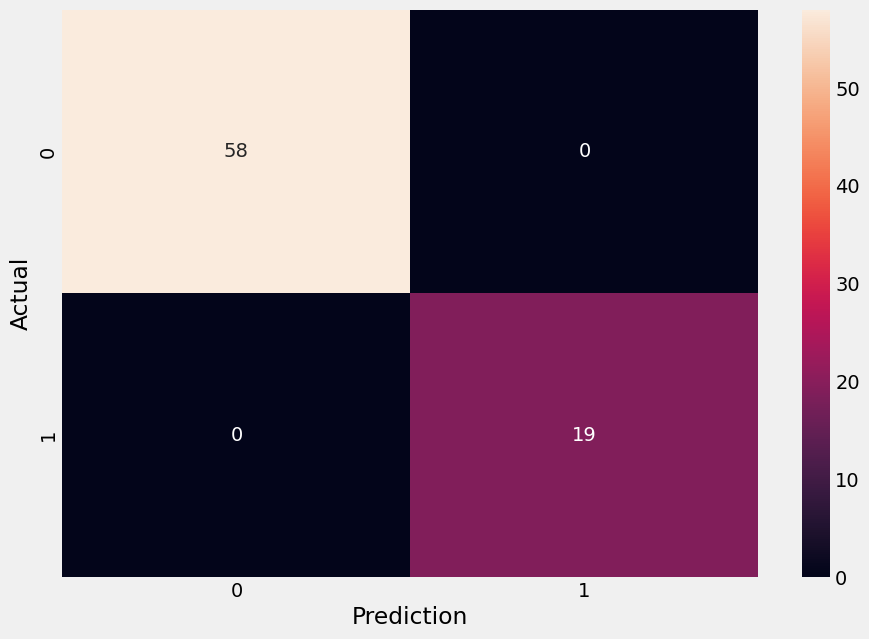

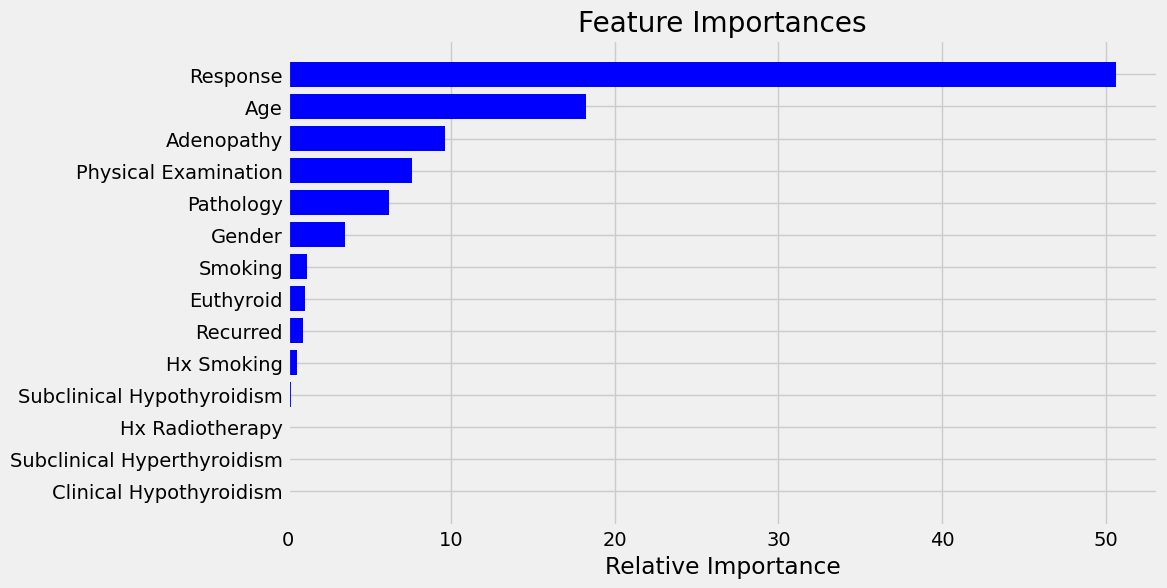

CatBoost Accuracy 1.0
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        58
           1       1.00      1.00      1.00        19

    accuracy                           1.00        77
   macro avg       1.00      1.00      1.00        77
weighted avg       1.00      1.00      1.00        77




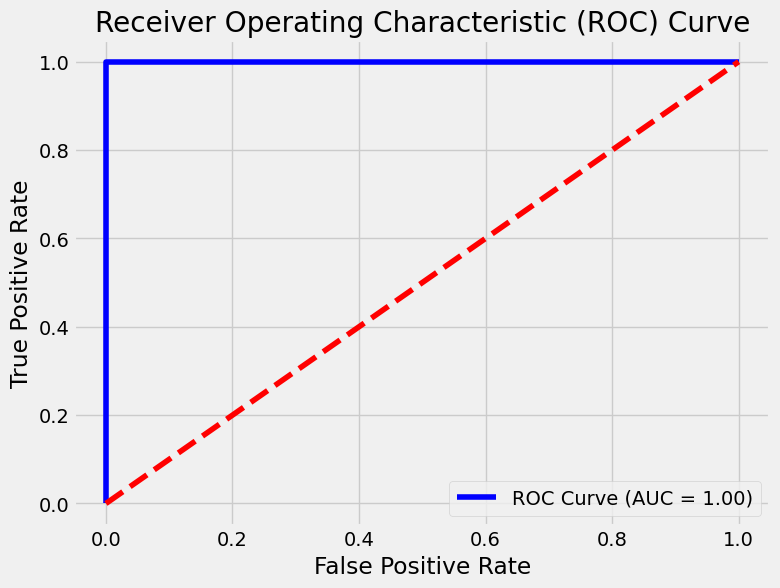

In [92]:
#instantiate classification models
models = {
    'CatBoost': CatBoostClassifier(verbose=0)
}

#fit models and generate classification reports
model_scores = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Evaluating the trained model's performance on the test data (X_test) and corresponding labels (y_test)
    model.score(X_test, y_test)

    metric = accuracy_score(y_test , y_pred)
    report = classification_report(y_test, y_pred)
    model_scores.append((name , metric, report))

    plt.figure(figsize=(10,7))
    sns.heatmap(confusion_matrix(y_test , y_pred) , annot=True , fmt='d')
    plt.xlabel('Prediction')
    plt.ylabel('Actual')
    
    # Feature importance
    feature_names = list(df.columns)
    feature_names.pop(10)

    if hasattr(model, "feature_importances_"):
        print("{0} Important Features".format(name))
        importances = model.feature_importances_
        indices = np.argsort(importances)

        # Plot feature importance
        plt.figure(figsize=(10, 6))
        plt.title('Feature Importances')
        plt.barh(range(len(indices)), importances[indices], color='b', align='center')
        plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
        plt.xlabel('Relative Importance')
        plt.show()

    print("{0} Accuracy {1}".format(name, accuracy_score(y_test, y_pred)))
    report = classification_report(y_test, y_pred)
    print(f'Classification Report:\n{report}\n')

    # Predict probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Compute ROC curve and AUC score
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    # Plot the ROC curve
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.2f})')
    plt.plot([0, 1], [0, 1], color='red', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.show()

# Explain Model Performance

In [93]:
# Create object that can calculate shap values
# explainer = shap.TreeExplainer(model)

# Calculate Shap values
#shap_values = explainer.shap_values(X_test)

#All Rows
#shap.summary_plot(shap_values, X_test)
#Single Row
#shap.summary_plot(shap_values[0], X_test)
#shap.plots.force(explainer.expected_value[1], shap_values[1][2,:], X_test.iloc[2, :], matplotlib = True)

#shap.initjs()
#shap.force_plot(explainer.expected_value[0], shap_values[0], X_test)

#shap.decision_plot(explainer.expected_value[0], shap_values[0], X_test.columns)
#shap.decision_plot(explainer.expected_value[1], shap_values[1], X_test.columns)
